# 03 — Temporal baseline experiments and test predictions

**Business question:** Does adding selected customer attributes improve prediction of a repeat purchase within 90 days?

We compare transaction-only and client-enriched logistic regression using identical purchase IDs, a chronological approximately 80/20 split and a 90-day gap. F1 for class 1 is the primary metric, as specified in the competition Evaluation screenshot supplied by the group. Predictions submitted to Kaggle are binary classes.

This is an intermediate baseline, not the complete final project: the final submission still requires at least five algorithms covered in class, feature-selection experiments, optimisation and an open-ended investigation. This notebook does not implement a random split. Group contributions and the final abstract must be maintained in the group's main deliverable.

**Protocol fixed before evaluation:** C=1, L2 regularisation, threshold=0.5, no class weighting and no hyperparameter or threshold search. Choose the feature set with the higher validation F1; prefer transaction-only on an exact tie. A single holdout used for selection is not an unbiased final performance estimate.

## 3.1 Imports and reproducibility
Run from the project root or `notebooks/`. Dependencies: pandas, numpy, matplotlib, scikit-learn and Jupyter. No internet access is needed to execute the notebook.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             roc_auc_score, ConfusionMatrixDisplay, confusion_matrix)

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'Run from the project root or notebooks/.'
DATA = ROOT / 'data'
OUT = ROOT / 'output' / 'notebook03'
OUT.mkdir(parents=True, exist_ok=True)
TARGET = 'repeat_purchase_90d'
SEED = 42
THRESHOLD = 0.5
CLIENT_FEATURES = ['country_or_region', 'commercial_region', 'island', 'customer_since_year']
print(f'pandas {pd.__version__}; scikit-learn {sklearn.__version__}')
display(Markdown('**Reproducibility:** versions are recorded because library defaults can change. All learned transformations belong inside each fitted pipeline.'))

pandas 3.0.3; scikit-learn 1.9.0


**Reproducibility:** versions are recorded because library defaults can change. All learned transformations belong inside each fitted pipeline.

## 3.2 Load and validate the official inputs
The customer table is optional enrichment. Identifiers support joins, checks and submission order, not model inputs. Raw CSVs are never modified.

In [2]:
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
clients = pd.read_csv(DATA / 'clientes.csv')
sample = pd.read_csv(DATA / 'sample_submission.csv')
assert TARGET in train and TARGET not in test
assert train[TARGET].notna().all() and set(train[TARGET].unique()) == {0, 1}
assert train['ID'].is_unique and test['ID'].is_unique
assert set(train['ID']).isdisjoint(test['ID'])
assert train.drop(columns=TARGET).columns.equals(test.columns)
assert sample.columns.tolist() == ['ID', TARGET]
assert sample['ID'].equals(test['ID'])
assert clients['customer_id'].is_unique and clients['customer_id'].notna().all()
for frame in [train, test]:
    assert frame['customer_id'].isin(clients['customer_id']).all()
display(pd.DataFrame({'file': ['train', 'test', 'clients', 'sample'],
                      'rows': [len(train), len(test), len(clients), len(sample)]}))
display(Markdown('**Conclusion:** schemas, unique row IDs, customer coverage and submission order passed the checks. The target is available only in train; test labels are never inferred or used.'))

,file,rows
0,train,6534
1,test,986
2,clients,1143
3,sample,986


**Conclusion:** schemas, unique row IDs, customer coverage and submission order passed the checks. The target is available only in train; test labels are never inferred or used.

## 3.3 Eligibility and deterministic cleaning
Apply the transaction rules documented in Notebooks 01–02. Rows with all transaction candidates missing are excluded from this controlled baseline, using the same mask before enrichment. They may have usable client attributes after joining, so this is a scope decision rather than proof that prediction is impossible. They also lack dates needed for this split. Test rows are never dropped.

Only four specifically audited historical fields are corrected. Negative intervals are invalid; negative historical monetary values are treated as invalid under the group's current interpretation of these features. Returns/credit notes would require revisiting that monetary assumption. Exact 1,000,000,000 values are treated as suspected corruption based on Notebook 01; ordinary large purchases are retained. No thresholds are estimated from validation or test. `random_noise` stays in both baselines; its removal needs a later controlled experiment.

In [3]:
candidate = [c for c in train if c not in [TARGET, 'ID', 'customer_id']]
empty = train[candidate].isna().all(axis=1)
train_dates = pd.to_datetime(train['purchase_date'], errors='coerce')
test_dates = pd.to_datetime(test['purchase_date'], errors='coerce')
eligible = (~empty) & train_dates.notna()
assert train_dates[eligible].max() + pd.Timedelta(days=90) < test_dates.min()
base = train.loc[eligible].copy().reset_index(drop=True)
base['purchase_date'] = pd.to_datetime(base['purchase_date'])

def clean_history(frame):
    result = frame.copy()
    for col in ['days_since_previous_purchase', 'prior_mean_gap_days']:
        result.loc[result[col] < 0, col] = np.nan
    for col in ['prior_mean_purchase_value', 'spend_365d']:
        result.loc[(result[col] < 0) | (result[col] == 1_000_000_000), col] = np.nan
    return result

quality = pd.DataFrame({'count': [len(train), int(empty.sum()),
    int((~empty & train_dates.isna()).sum()), len(base)]},
    index=['Original train', 'Almost-empty excluded', 'Other missing dates excluded', 'Eligible train'])
display(quality)
display(Markdown(f'**Conclusion:** {len(base):,} purchases are eligible; {len(train)-len(base):,} are excluded. Both experiments will use exactly these same purchases. Final refitting can use every eligible dated training purchase because all their 90-day windows end before the first test purchase.'))

,count
Original train,6534
Almost-empty excluded,65
Other missing dates excluded,0
Eligible train,6469


**Conclusion:** 6,469 purchases are eligible; 65 are excluded. Both experiments will use exactly these same purchases. Final refitting can use every eligible dated training purchase because all their 90-day windows end before the first test purchase.

## 3.4 One chronological split and the 90-day gap
Sort eligible purchase dates and take the date at position `floor(0.8 × N)` as the validation start. All purchases on that date stay together. Train uses dates **strictly earlier** than validation start minus 90 days. The intervening rows are excluded from this evaluation, not assigned to validation.

This conservative gap ensures that the full 90-day target window of every training purchase ends before validation begins. Historical predictors are assumed to have been computed using information available at each purchase; a gap cannot repair predictors that already contain future information. Repeated customers are allowed because forecasting future purchases of known customers is part of the intended task.

In [4]:
ordered_dates = base['purchase_date'].sort_values().reset_index(drop=True)
validation_start = ordered_dates.iloc[int(np.floor(0.8 * len(base)))]
train_end_exclusive = validation_start - pd.Timedelta(days=90)
fit_mask = base['purchase_date'] < train_end_exclusive
val_mask = base['purchase_date'] >= validation_start
gap_mask = ~(fit_mask | val_mask)
assert not (fit_mask & val_mask).any()
assert fit_mask.sum() + gap_mask.sum() + val_mask.sum() == len(base)
assert base.loc[fit_mask, 'purchase_date'].max() + pd.Timedelta(days=90) < validation_start
assert base.loc[fit_mask, TARGET].nunique() == base.loc[val_mask, TARGET].nunique() == 2
parts = {'Train': fit_mask, '90-day gap': gap_mask, 'Validation': val_mask}
split_table = pd.DataFrame([{
    'partition': name, 'rows': int(mask.sum()),
    '% eligible': 100 * mask.sum() / len(base),
    '% original train': 100 * mask.sum() / len(train),
    'first purchase': base.loc[mask, 'purchase_date'].min(),
    'last purchase': base.loc[mask, 'purchase_date'].max(),
    'positive rate': base.loc[mask, TARGET].mean(),
    'customers': base.loc[mask, 'customer_id'].nunique()
} for name, mask in parts.items()]).set_index('partition')
display(split_table.round({'% eligible': 2, '% original train': 2, 'positive rate': 4}))
shared = len(set(base.loc[fit_mask, 'customer_id']) & set(base.loc[val_mask, 'customer_id']))
display(Markdown(f'**Conclusion:** validation starts on {validation_start.date()}; training dates are before {train_end_exclusive.date()}. Training contains {fit_mask.sum()/len(base):.2%}, the gap {gap_mask.sum()/len(base):.2%}, and validation {val_mask.sum()/len(base):.2%} of eligible rows. Thus 80/20 describes the initial cut, not the final training percentage. There are {shared} customers shared by train and validation. Positive-rate differences describe temporal drift; they do not justify changing the cut after seeing scores.'))
split_table.to_csv(OUT / 'temporal_split_summary.csv')
assignment = base[['ID', 'purchase_date']].copy()
assignment['partition'] = np.select([fit_mask, val_mask], ['train', 'validation'], default='gap')
assignment.to_csv(OUT / 'split_assignments.csv', index=False)

,rows,% eligible,% original train,first purchase,last purchase,positive rate,customers
partition,,,,,,,
Train,5024,77.66,76.89,2015-07-11,2023-03-18,0.5498,557
90-day gap,147,2.27,2.25,2023-03-20,2023-06-13,0.5170,107
Validation,1298,20.06,19.87,2023-06-17,2025-02-15,0.6032,241


**Conclusion:** validation starts on 2023-06-17; training dates are before 2023-03-19. Training contains 77.66%, the gap 2.27%, and validation 20.06% of eligible rows. Thus 80/20 describes the initial cut, not the final training percentage. There are 194 customers shared by train and validation. Positive-rate differences describe temporal drift; they do not justify changing the cut after seeing scores.

## 3.5 Feature sets and safe customer integration
The transaction baseline uses all 29 numeric and six categorical transaction/history predictors. Exclude target, row ID, customer ID and purchase date. Date is used only for validation in this experiment. The enriched baseline adds four attributes selected in Notebook 02; customer-entry year is categorical.

This is an explicit comparison of feature sets, not a completed feature-selection search. We assume client attributes were available and stable at the purchase date. Entry year not exceeding purchase year is a consistency check, not proof of historical availability. In particular, current region or island might have changed.

In [5]:
def enrich(frame):
    joined = frame.merge(clients[['customer_id'] + CLIENT_FEATURES],
                         on='customer_id', how='left', validate='many_to_one', sort=False)
    assert len(joined) == len(frame) and joined['ID'].equals(frame['ID'])
    joined['customer_since_year'] = joined['customer_since_year'].astype(str)
    return joined

clean_base = clean_history(base)
enriched_base = enrich(clean_base)
transaction_features = [c for c in test.columns if c not in ['ID', 'customer_id', 'purchase_date']]
feature_sets = {'transaction_only': transaction_features,
                'client_enriched': transaction_features + CLIENT_FEATURES}
frames = {'transaction_only': clean_base, 'client_enriched': enriched_base}
for name, features in feature_sets.items():
    assert not set([TARGET, 'ID', 'customer_id', 'purchase_date']) & set(features)
    print(name, len(features), 'features:', features)
display(Markdown('**Conclusion:** the enriched model differs only by four client attributes. IDs, target, purchase date, sample predictions and partition membership cannot enter either model. Join checks preserve row alignment. High-cardinality client addresses/names and the entirely missing customer_type are excluded as documented in Notebook 02.'))

transaction_only 35 features: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'random_noise']
client_enriched 39 features: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'p

**Conclusion:** the enriched model differs only by four client attributes. IDs, target, purchase date, sample predictions and partition membership cannot enter either model. Join checks preserve row alignment. High-cardinality client addresses/names and the entirely missing customer_type are excluded as documented in Notebook 02.

## 3.6 Preprocessing and logistic regression
Numeric fields: training-median imputation with missing indicators, then standardisation. Categorical fields: explicit `Missing` value and one-hot encoding with unseen validation/test categories ignored. Unknown categories therefore have all-zero indicators for that field.

L2-regularised logistic regression provides a simple baseline; standardisation prevents large currency scales from dominating the penalty. C=1, threshold=0.5 and the feature lists are fixed. No resampling or class weights are introduced. A high iteration limit is a convergence safeguard, not a hyperparameter search. Missing indicators are created for fields missing during fitting; later-only missingness is still imputed but may not receive a new indicator.

In [6]:
def make_pipeline(frame, features):
    numeric = frame[features].select_dtypes(include='number').columns.tolist()
    categorical = [c for c in features if c not in numeric]
    numeric_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
        ('scale', StandardScaler())])
    categorical_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='Missing', keep_empty_features=True)),
        ('encode', OneHotEncoder(handle_unknown='ignore'))])
    preprocess = ColumnTransformer([('numeric', numeric_pipe, numeric),
                                    ('categorical', categorical_pipe, categorical)])
    return Pipeline([('preprocess', preprocess),
                     ('model', LogisticRegression(C=1.0, solver='lbfgs', max_iter=10000,
                                                  random_state=SEED))])

def fit_checked(pipeline, X, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        pipeline.fit(X, y)
    if any(issubclass(w.category, ConvergenceWarning) for w in caught):
        raise RuntimeError('Logistic regression did not converge; inspect preprocessing before reporting results.')
    return pipeline

print('Pipeline factory ready; no model has been fitted yet.')
display(Markdown('**Conclusion:** all medians, scales and category vocabularies will be learned exclusively from the training partition. Validation and test are transformed using these fitted quantities.'))

Pipeline factory ready; no model has been fitted yet.


**Conclusion:** all medians, scales and category vocabularies will be learned exclusively from the training partition. Validation and test are transformed using these fitted quantities.

## 3.7 Controlled experiments and simple reference models
Primary metric: positive-class F1 at threshold 0.5, matching the competition. Precision and recall explain its trade-off; accuracy and ROC-AUC provide secondary context. ROC-AUC uses probabilities and does not choose the winner. Constant-positive and most-frequent baselines show whether the model improves on trivial rules; F1 can be relatively high even when predicting everyone as positive.

In [7]:
y_fit = base.loc[fit_mask, TARGET]
y_val = base.loc[val_mask, TARGET]
def scores(name, predictions, probabilities):
    return {'model': name, 'f1': f1_score(y_val, predictions, zero_division=0),
            'precision': precision_score(y_val, predictions, zero_division=0),
            'recall': recall_score(y_val, predictions, zero_division=0),
            'accuracy': accuracy_score(y_val, predictions),
            'roc_auc': roc_auc_score(y_val, probabilities)}

results, fitted, predictions, probabilities = [], {}, {}, {}
for strategy in ['most_frequent', 'constant']:
    dummy = DummyClassifier(strategy=strategy, constant=1 if strategy == 'constant' else None)
    dummy.fit(np.zeros((len(y_fit), 1)), y_fit)
    pred = dummy.predict(np.zeros((len(y_val), 1)))
    prob = dummy.predict_proba(np.zeros((len(y_val), 1)))[:, 1]
    results.append(scores('dummy_' + strategy, pred, prob))

for name, features in feature_sets.items():
    frame = frames[name]
    pipeline = fit_checked(make_pipeline(frame, features), frame.loc[fit_mask, features], y_fit)
    prob = pipeline.predict_proba(frame.loc[val_mask, features])[:, 1]
    pred = (prob >= THRESHOLD).astype(int)
    fitted[name], predictions[name], probabilities[name] = pipeline, pred, prob
    results.append(scores(name, pred, prob))
    assert len(pred) == val_mask.sum() and np.isfinite(prob).all()

metrics = pd.DataFrame(results).set_index('model')
display(metrics.round(4))
delta = metrics.loc['client_enriched', 'f1'] - metrics.loc['transaction_only', 'f1']
selected = 'client_enriched' if delta > 0 else 'transaction_only'
best_dummy = metrics.loc[['dummy_most_frequent', 'dummy_constant'], 'f1'].max()
display(Markdown(f'**Conclusion:** client enrichment changes validation F1 by {delta:+.4f} ({delta*100:+.2f} percentage points). Under the predefined rule, **{selected}** is selected, with F1={metrics.loc[selected, "f1"]:.4f}. The best dummy F1 is {best_dummy:.4f}. This is a descriptive result from one period, not evidence of statistical significance or a guarantee of future improvement. If a dummy is better, that limitation must be reported even though selection here is between the two planned logistic regressions.'))
metrics.to_csv(OUT / 'validation_metrics.csv')

,f1,precision,recall,accuracy,roc_auc
model,,,,,
dummy_most_frequent,0.7525,0.6032,1.0000,0.6032,0.5000
dummy_constant,0.7525,0.6032,1.0000,0.6032,0.5000
transaction_only,0.7525,0.7971,0.7126,0.7173,0.7840
client_enriched,0.7539,0.7986,0.7139,0.7188,0.7883


**Conclusion:** client enrichment changes validation F1 by +0.0013 (+0.13 percentage points). Under the predefined rule, **client_enriched** is selected, with F1=0.7539. The best dummy F1 is 0.7525. This is a descriptive result from one period, not evidence of statistical significance or a guarantee of future improvement. If a dummy is better, that limitation must be reported even though selection here is between the two planned logistic regressions.

## 3.8 Interpret errors on the same validation purchases
Rows of each confusion matrix are true classes and columns are predictions. False positives represent customers predicted to return who do not; false negatives are returning customers the model misses. These errors have different commercial implications, but no monetary costs were supplied, so we do not claim an optimal business threshold.

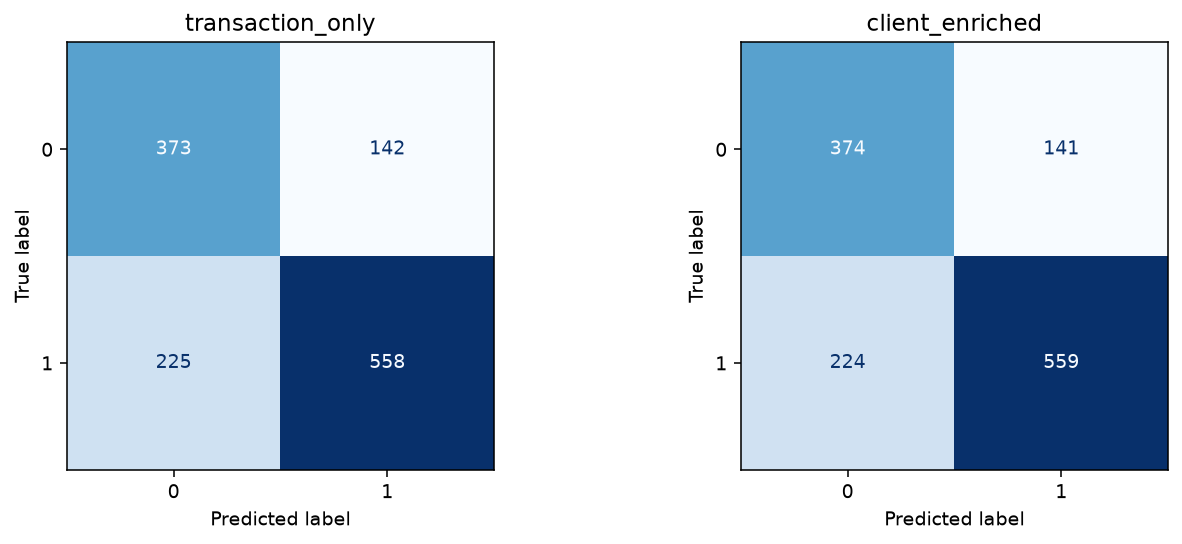

**Conclusion:** the selected model has 559 true positives, 374 true negatives, 141 false positives and 224 false negatives. Precision is 79.9% and recall is 71.4%. Enrichment should be assessed through these changes as well as F1. We do not tune the threshold on this holdout; doing so would add another selection step and make its score more optimistic.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, feature_sets):
    ConfusionMatrixDisplay.from_predictions(y_val, predictions[name], labels=[0, 1],
                                           ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout()
from io import BytesIO
from IPython.display import Image
figure_buffer = BytesIO()
fig.savefig(figure_buffer, format='png', dpi=140, bbox_inches='tight')
display(Image(data=figure_buffer.getvalue()))
plt.close(fig)
tn, fp, fn, tp = confusion_matrix(y_val, predictions[selected], labels=[0, 1]).ravel()
display(Markdown(f'**Conclusion:** the selected model has {tp} true positives, {tn} true negatives, {fp} false positives and {fn} false negatives. Precision is {metrics.loc[selected, "precision"]:.1%} and recall is {metrics.loc[selected, "recall"]:.1%}. Enrichment should be assessed through these changes as well as F1. We do not tune the threshold on this holdout; doing so would add another selection step and make its score more optimistic.'))
validation_predictions = base.loc[val_mask, ['ID', 'customer_id', 'purchase_date', TARGET]].copy()
for name in feature_sets:
    validation_predictions[name + '_prediction'] = predictions[name]
    validation_predictions[name + '_probability'] = probabilities[name]
validation_predictions.to_csv(OUT / 'validation_predictions.csv', index=False)

## 3.9 Refit the chosen feature set and predict test
After selection, build a fresh pipeline and fit all eligible training rows, including the gap and validation purchases. They were withheld for evaluation, not permanently unusable. The original holdout metrics remain the evaluation record; refitting does not produce a new validation score.

All eligible training targets have completed their 90-day windows before the earliest test date. Client temporal availability remains an assumption. Every test row must receive one binary prediction, in the original sample order. The CSV is generated locally; no Kaggle upload is performed.

In [9]:
final_features = feature_sets[selected]
final_train = frames[selected]
clean_test = clean_history(test)
final_test = enrich(clean_test) if selected == 'client_enriched' else clean_test
final_pipeline = fit_checked(make_pipeline(final_train, final_features),
                             final_train[final_features], base[TARGET])
test_probability = final_pipeline.predict_proba(final_test[final_features])[:, 1]
test_prediction = (test_probability >= THRESHOLD).astype(int)
submission = sample[['ID']].copy()
submission[TARGET] = test_prediction
assert submission.columns.tolist() == sample.columns.tolist()
assert submission['ID'].equals(test['ID']) and len(submission) == len(test)
assert submission.notna().all().all() and set(submission[TARGET].unique()) <= {0, 1}
submission_path = OUT / 'submission_logistic_temporal.csv'
submission.to_csv(submission_path, index=False)
reloaded = pd.read_csv(submission_path)
pd.testing.assert_frame_equal(reloaded, submission)
display(submission.head())
display(submission[TARGET].value_counts().rename('predictions').to_frame())
display(Markdown(f'**Conclusion:** refitted **{selected}** on {len(base):,} eligible purchases and generated {len(submission):,} binary predictions. Predicted repeat-purchase proportion: {submission[TARGET].mean():.1%}. This proportion is not test accuracy: true test targets are unavailable. The CSV passed a read-back check and is saved at `{submission_path}`.'))
manifest = {'selected_feature_set': selected, 'primary_metric': 'positive-class F1',
            'threshold': THRESHOLD, 'validation_start': str(validation_start.date()),
            'train_end_exclusive': str(train_end_exclusive.date()), 'gap_days': 90,
            'eligible_rows': len(base), 'excluded_rows': int((~eligible).sum()),
            'features': final_features, 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
            'model': 'LogisticRegression(C=1, solver=lbfgs, max_iter=10000)',
            'selection_rule': 'Higher validation F1; exact tie favours transaction_only'}
(OUT / 'experiment_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')

,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,0
3,10000020,0
4,10000025,0


,predictions
repeat_purchase_90d,
1,575
0,411


**Conclusion:** refitted **client_enriched** on 6,469 eligible purchases and generated 986 binary predictions. Predicted repeat-purchase proportion: 58.3%. This proportion is not test accuracy: true test targets are unavailable. The CSV passed a read-back check and is saved at `C:\Users\mmart\Documents\ML_Group_04\output\notebook03\submission_logistic_temporal.csv`.

1392

## 3.10 Findings, limitations and defence notes
The result statements above are calculated from the actual outputs and update on rerun. A successful execution establishes reproducibility of this baseline, not completion of all final-project requirements.

- **Why not random splitting?** The target concerns future behaviour. Chronological evaluation better matches deployment, while random splitting can place future purchases in training relative to validation purchases.
- **Why a gap?** Each training label describes the next 90 days. Its observation window must finish before validation starts.
- **Why are customers shared?** The task includes future purchases of known customers. Generalising to entirely new customers is a separate question needing another evaluation.
- **Why is the final training set larger?** Once evaluation is recorded, all eligible labelled purchases may train the final pipeline; their labels mature before test begins.
- **What does enrichment establish?** Only a paired comparison for one model and one temporal holdout. Purchases from the same customer are dependent; small score differences should not be called significant.
- **What is still uncertain?** Historical availability of customer attributes, the interpretation of negative monetary histories, excluded undated rows and changes across time. Missingness associations and feature choices were explored using the supplied train in earlier notebooks, so this holdout is not completely untouched by exploratory decisions.
- **What comes later?** At least five class-covered algorithms, justified feature selection, optimisation using inner temporal validation (including threshold tuning if desired), and an open-ended study. Keep a later evaluation period untouched if a less biased final estimate is required. Do not repeatedly adapt to the Kaggle public score.

**Sources and provenance:** supplied project guidelines; Notebooks 01 and 02 for the cleaning and client-feature decisions; official CSV files; group-supplied Kaggle Evaluation screenshot confirming F1. The screenshot is the source for the competition metric, not for a particular threshold. No external performance claims or invented results are used.